# **Exploratory Data Analysis: Social Anxiety Dataset**
#### *Cross Analysis: Social Anxiety Relevant to Demographics, Lifestyle, and Stress*
### **Graeme Jeffreys**

--- 
### *Note: all sections with a **Bolded** description in brackets highlight the required elements and order.
## Contents:
1. Title and information (**Title**)
2. Table of Contents
3.  Introduction (**Introduction**)
    - Purpose of EDA
    - Question
4. Question: *Analysis of multiple variables*
5. Data breakdown
    - Dataset groups
    - CSV columns listed as imported from dataset.
6. Import libraries and Modified CSV - variable relevance
    - Import Libraries: Pandas, Seaborn, Matplotlib
    - Clean Data 
7. Data Examination (**Analysis**)
    - Columns
        - Age
            - Range
        - Gender 
            - Identify unique vlaues
            - Unique populations vs. total population
            - Population percentage, mean, and deviation
            - Minor data visualization to display diversity in population
        - Sleep Hours Average per night
            - Min, Max and Mean
        - Physical Activity (Hrs/week)
            - Min, Max and Mean
        - Family History of anxiety
            - Sum of Yes and No
        - Stress Level
            - Min, Max and Mean
        - Recent Major Life Event
            - Sum of Yes and No
        - Diet Quality Rating (1-10)
            - Min, Max and Mean
        - Diet Quality Rating (1-10)
            - Min, Max and Mean
        - **Social Anxiety Level**
            - Min, Max, and Mean
    - Data Groups (***Further* Analysis**)
        - Demogrpahics
            - Regression lines of age and gender vs anxiety level
            - Data Visualization
        - Lifestyle
            - All lifestyle factors vs. anxiety with regression lines
            - Mean regression line for Lifestyle Factors
            - Data Visualization
        - Stress Factor
            - Mean regression line for Stress level (Stress Factor)
            - Data Visualization
8. Discussion (**Discussion**)
    - Summary and analysis of graphs and numbers from "Data Examination" section (above)
9. Gen AI Disclosure (**Gen AI Disclosure**)
10. Data source and citation (**References**)  

## **Introduction:**
#### This exploratory data analysis looks at social anxiety and how it could be affected by demographic, lifestyle, and stress-related factors. By examining patterns and relationships in the data, the goal would be to find out which factors, or combinations of factors, are linked to different levels of reported social anxiety. As seen above, the CSV data used is from Kaggle.com, with the reference and link provided.
### **Purpose:**
#### *This exploratory data analysis is an exploration into **Social Anxiety** and the influence of  **Demographics, Lifestyle, and Stress Factors** on reported levels of social anxiety. The analysis evaluates correlations among variables and social anxiety scores in order to identify any factors associated with variations in the reported Social Anxiety scores.*
### **Question**
#### *"How do combinations of demographic, lifestyle, or stress factor variables influence higher or lower social anxiety levels?"*
---
### **Data Breakdown:**
##### **Demographics:** Age, Gender
##### **Lifestyle:** Average sleep (hrs/wk), Physical activiy (hrs/week), Diet quality (scale: 1-10)
##### **Stress Factors:** Stress level (scale: 1-10)
##### **Social Anxiety Level:** Scale: 1-10
#####   
##### **Other noteworthy data:** The **Recent Major Life Event**, and **Family History of Anxiety** are examined but not directly analyzed in conjunction with anxiety levels.
---
##### **CSV Columns as imported:** *Age, Gender, Sleep Hours, Physical Activity (hrs/week), Family History of Anxiety, Stress Level (1-10), Recent Major Life Event, Diet Quality (1-10), Anxiety Level (1-10)*
---

### IMPORT: 
 
#### 
*Import numpy and pandas*

#### 
*Import seaborn and matplot*

###
*Assign csv to data frame (df)*


In [346]:
# import numpy, pandas, seaborn, and matplotlib 
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('enhanced_anxiety_dataset_mod.csv')

### Clean Data:
*Ensure Data is clean, and there are no non-values or missing data fields.*

In [347]:
# drop rows that are missing any pieces of data and count how many

# make count
dropped_rows = len(df)
print (dropped_rows)

# drop rows with any missing fields
df = df.dropna()
#print(df)

# print length after drop
print(len(df))


11000
11000


### **Data Examination:**
#### **COLUMNS & DATA GROUPS:**
##### AGE

In [348]:
# Examine the range of age
if 'Age' in df.columns:
    age_max = df['Age'].max()
    age_min = df['Age'].min()
    print("Max age: " + str(age_max))
    print("Min age: " + str(age_min))
else: 
    print("incorrect column name readjust")

# use groupby to determine mean age


Max age: 64
Min age: 18


Within a fairly good range which will be able to determine if age has any correlation with anxiety.

##### GENDER:
###### 1. *Identify the unique values of Gender.*
###### 2. *Determine total of each unique population and how much of the total dataset population it is.*
###### 3. *Calculate % of total for each unique population, the mean, and the deviation % for each gender*
###### 4. *Print results, and graph relative data in bar graphs.*

In [349]:
# identify unique values
print(df["Gender"].unique())

['Female' 'Other' 'Male']


In [350]:
# loop through for totals of each gender in data populace and determine % populations
# totals
countM=0
countF=0
countO=0
countNaN=0

# count pop
for gender in df["Gender"]:
    if gender == "Male":
        countM += 1
    elif gender == "Female":
        countF += 1
    elif gender == "Other":
        countO += 1
    else:
        countNaN += 1

# gather total populace (11k)
totalPop = countM+countF+countO

# determine percentages of each unique value to total pop
percM = (countM/totalPop)*100
percF = (countF/totalPop)*100
percO = (countO/totalPop)*100
percNan = (countNaN/totalPop)*100

# print totals
print("Males: " + str(countM))
print("Female: " + str(countF))
print("Others: " + str(countO))
print("----Outlier or NaN: " + str(countNaN))

# print percentages
print("\n\nMale population % of total: " + str(round(percM, 2)) + "%")
print("Female population % of total: " + str(round(percF, 2)) + "%")
print("Other population % of total: " + str(round(percO, 2)) + "%")
print("----NaN population % of total: " + str(round(countNaN, 2)) + "%")

##### calculate mean percentage relative to mean population 
meanPerc = (percM + percF + percO) / 3

# print mean
print("\nMean value as percentage: " + str(round(meanPerc, 2)) + "%")

# deviations from the mean
devM = percM - meanPerc
devF = percF - meanPerc
devO = percO - meanPerc

# print deviations
print("\nDeviation from average population %:")
print("Male deviation: " + str(round(devM, 2)) + "%")
print("Female deviation: " + str(round(devF, 2)) + "%")
print("Other deviation: " + str(round(devO, 2)) + "%")


Males: 3657
Female: 3730
Others: 3613
----Outlier or NaN: 0


Male population % of total: 33.25%
Female population % of total: 33.91%
Other population % of total: 32.85%
----NaN population % of total: 0%

Mean value as percentage: 33.33%

Deviation from average population %:
Male deviation: -0.09%
Female deviation: 0.58%
Other deviation: -0.49%


###### *Identified more females in study as dominant populace by a factor of 0.58% of mean*


C:\Users\g-lap\AppData\Local\Temp\ipykernel_27420\711475582.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Gender", y="Counts", data=data, palette=["blue", "pink", "green"])


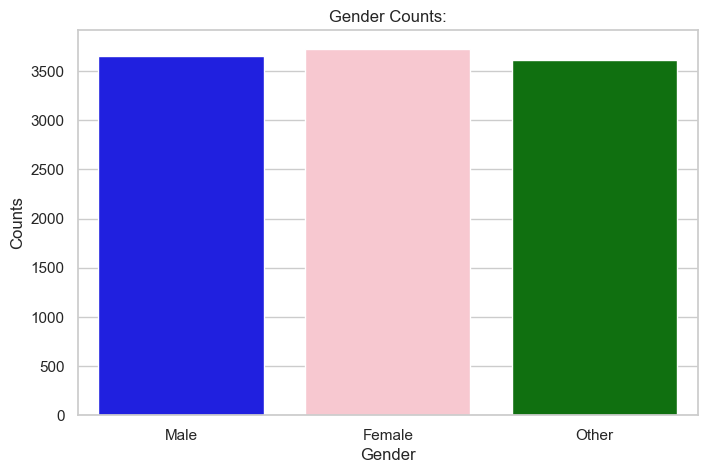

C:\Users\g-lap\AppData\Local\Temp\ipykernel_27420\711475582.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Gender", y="Percentages", data=data, palette=["blue", "pink", "green"])


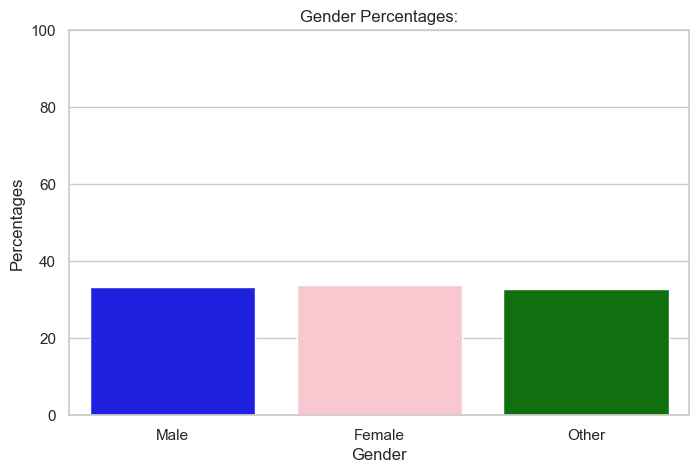

C:\Users\g-lap\AppData\Local\Temp\ipykernel_27420\711475582.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Gender", y="Deviations", data=data, palette=["blue", "pink", "green"])


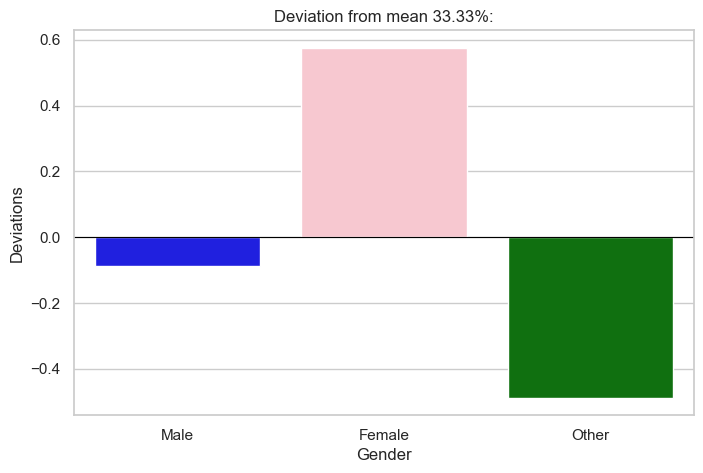

In [351]:
data = pd.DataFrame({
    "Gender": ["Male", "Female", "Other"],
    "Counts": [countM, countF, countO],
    "Percentages": [percM, percF, percO],
    "Deviations": [devM, devF, devO]
})

sns.set_style("whitegrid")

# count graph
plt.figure(figsize=(8,5))
sns.barplot(x="Gender", y="Counts", data=data, palette=["blue", "pink", "green"])
plt.title("Gender Counts:")
plt.show()

# perc graph
plt.figure(figsize=(8,5))
sns.barplot(x="Gender", y="Percentages", data=data, palette=["blue", "pink", "green"])
plt.title("Gender Percentages:")
plt.ylim(0, 100)  # percentages range
plt.show()

# deviation graph
plt.figure(figsize=(8,5))
sns.barplot(x="Gender", y="Deviations", data=data, palette=["blue", "pink", "green"])
plt.axhline(0, color='black', linewidth=0.8)  # reference line at 0
plt.title("Deviation from mean 33.33%:")
plt.show()

*No significant large group, very equal and well distributed which is ideal for reducing bias. Larger female population, then male, then other.*


##### SLEEP HOURS AVG

In [352]:
# Examine the range of avg sleep hrs (per night)
if 'Age' in df.columns:
    sleep_max = df['Sleep Hours'].max()
    sleep_min = df['Sleep Hours'].min()
    sleep_mean = df['Sleep Hours'].mean()
    print("Max sleep: " + str(sleep_max))
    print("Min sleep: " + str(sleep_min))
    print("Mean sleep: " + str(round(sleep_mean, 2)))
else: 
    print("incorrect column name readjust")

Max sleep: 11.3
Min sleep: 2.3
Mean sleep: 6.65


Relatively normal/low average sleep


##### PHYSICAL ACTIVITY (HOURS/WEEK)

In [353]:
# Examine the range of physical activity per week
if 'Physical Activity (hrs/week)' in df.columns:
    activity_max = df['Physical Activity (hrs/week)'].max()
    activity_min = df['Physical Activity (hrs/week)'].min()
    activity_mean = df['Physical Activity (hrs/week)'].mean()
    print("Max physical activity hr/w:", activity_max)
    print("Min physical activity hr/w:", activity_min)
    print("Mean physical activity hr/w:", round(activity_mean, 2))

else:
    print("Incorrect column name — readjust")

Max physical activity hr/w: 10.1
Min physical activity hr/w: 0.0
Mean physical activity hr/w: 2.94


Overall low average weekly physical activity amongst the population

##### FAMILY HISTORY OF ANXIETY

In [354]:
# Examine the difference in family history
if 'Family History of Anxiety' in df.columns:
    famHistoryY = (df['Family History of Anxiety'] == 'Yes').sum()
    famHistoryN = (df['Family History of Anxiety'] == 'No').sum()
    print("Family history yes:", famHistoryY)
    print("Family history no:", famHistoryN)
else: 
    print("incorrect column name readjust")


Family history yes: 5847
Family history no: 5153


Fairly even

##### STRESS LEVEL (AT TIME OF COLLECTION)

In [355]:
# Examine the range of stress level
if 'Stress Level (1-10)' in df.columns:
    stress_max = df['Stress Level (1-10)'].max()
    stress_min = df['Stress Level (1-10)'].min()
    stress_mean = df['Stress Level (1-10)'].mean()
    print("Max stress: " + str(stress_max))
    print("Min stress: " + str(stress_min))
    print("Mean stress: " + str(round(stress_mean, 2)))
else: 
    print("incorrect column name readjust")

Max stress: 10
Min stress: 1
Mean stress: 5.86


Moderate mean stress level across the population.

##### RECENT MAJOR LIFE EVENT

In [356]:
# Examine the difference in major life events
if 'Recent Major Life Event' in df.columns:
    lifeEvent_countY = (df['Recent Major Life Event'] == 'Yes').sum()
    lifeEvent_countN = (df['Recent Major Life Event'] == 'No').sum()
    print("Major life events:", lifeEvent_countY)
    print("No major life events:", lifeEvent_countN)
else: 
    print("incorrect column name readjust")

Major life events: 5623
No major life events: 5377


Fairly even distribution of individuals post major life event and not.

##### DIET QUALITY

In [357]:
# Examine the range of diet
if 'Diet Quality (1-10)' in df.columns:
    diet_max = df['Diet Quality (1-10)'].max()
    diet_min = df['Diet Quality (1-10)'].min()
    diet_mean = df['Diet Quality (1-10)'].mean()
    print("Max diet qual: " + str(diet_max))
    print("Min diet qual: " + str(diet_min))
    print("Mean diet qual: " +  str(round(diet_mean, 2)))
else: 
    print("incorrect column name readjust")

Max diet qual: 10
Min diet qual: 1
Mean diet qual: 5.18


Fairly even diet range due to observed mean. Although 5.28 could indicate average low score for diet quality.


##### SOCIAL ANXIETY LEVEL

In [358]:
# Examine the range of anxiety
if 'Anxiety Level (1-10)' in df.columns:
    anx_max = df['Anxiety Level (1-10)'].max()
    anx_min = df['Anxiety Level (1-10)'].min()
    anx_mean = df['Anxiety Level (1-10)'].mean()
    print("Max anxiety: " + str(anx_max))
    print("Min anxiety: " + str(anx_min))
    print("Mean anxiety:", round(activity_mean, 2))
else: 
    print("incorrect column name readjust")

Max anxiety: 10
Min anxiety: 1
Mean anxiety: 2.94


Moderately low anxiety level mean - curious how the data will correlate.

#### **Data Groups**
#### Demographics:
##### *Creates regression lines for all three genders relative to age and anxiety level.*

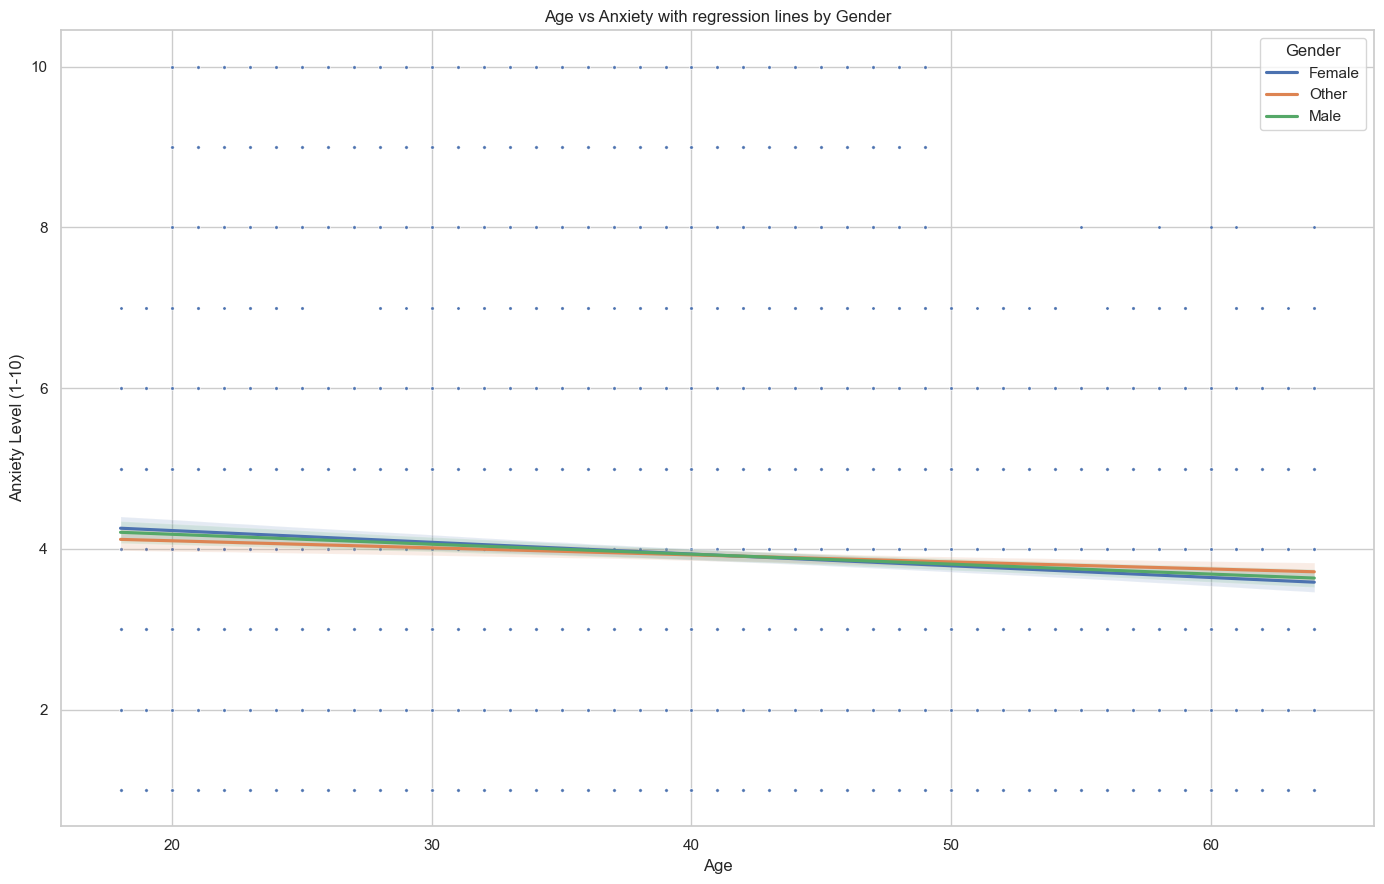

In [ ]:
# create columns
anx_col = 'Anxiety Level (1-10)'
age_col = 'Age'
gender_col = 'Gender'

genders = df[gender_col].unique().tolist()

# create matplotlib figure
plt.figure(figsize=(14, 9))
sns.scatterplot(x=age_col, 
                y=anx_col, 
                data=df, 
                s=5)

# regression line for each gender male, female, other
for g in genders:
    # create a copy of df to use for this specific data visualization
    sub = df[df[gender_col] == g]
    if sub[age_col].sum() < 2 or sub[anx_col].sum() < 2:
        continue
    # creates regression line plot
    sns.regplot(x=age_col, 
                y=anx_col, 
                data=sub, 
                scatter=False, # makes scatter points smaller apparently after testing various options
                label=str(g)) # used for the legend when autopoulating the genders

# show axis and title
plt.xlabel('Age')
plt.ylabel('Anxiety Level (1-10)')
plt.title('Age vs Anxiety with regression lines by Gender')

# show legend using the labels created
plt.legend(title='Gender')

# keeps all title, axis, legend, etc from overlapping or cutting off
plt.tight_layout()

##### *Creates a mean regression line to compare the Demopgraphic Factor to anxiety.*

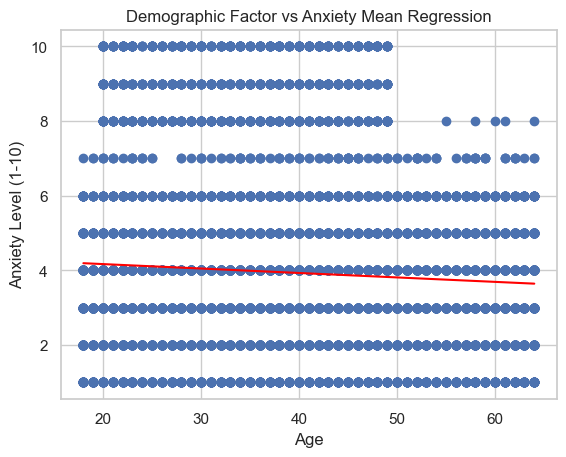

In [360]:
# create columns
anx_col = 'Anxiety Level (1-10)'
age_col = 'Age'
gender_col = 'Gender'

# create two arrays for slopes and intercepts
slopes = []
intercepts = []

# fit regression line for each gender subgroup
for g in df[gender_col].unique():
    sub = df[df[gender_col] == g]
    # get factor value and anxiety value at that point
    x = sub[age_col]
    y = sub[anx_col]
    x_mean = x.mean()
    y_mean = y.mean()
    # get mean slope
    m = ((x - x_mean) * (y - y_mean)).sum() / ((x - x_mean)**2).sum()
    # get intercepts
    b = y_mean - m * x_mean
    # append values to slopes and intercepts
    slopes.append(m)
    intercepts.append(b)

# mean slope and intercept
mean_slope = sum(slopes) / len(slopes)
mean_intercept = sum(intercepts) / len(intercepts)

# plot scatterplot
plt.scatter(df[age_col], 
            df[anx_col])

# plot mean regression line
x_line = [df[age_col].min(), df[age_col].max()]
# find y values for the slope, start at min to max (2 values in the xline array)
x1 = x_line[0]
x2 = x_line[1]
y1 = mean_intercept + mean_slope * x1
y2 = mean_intercept + mean_slope * x2

y_line = [y1, y2]

# plot the regression line
plt.plot(x_line, y_line, color='Red')

plt.xlabel('Age')
plt.ylabel('Anxiety Level (1-10)')
plt.title('Demographic Factor vs Anxiety Mean Regression');

#### **Lifestyle:**
##### *Compares all the lifestyle factors with anxiety and plots with regression line.*

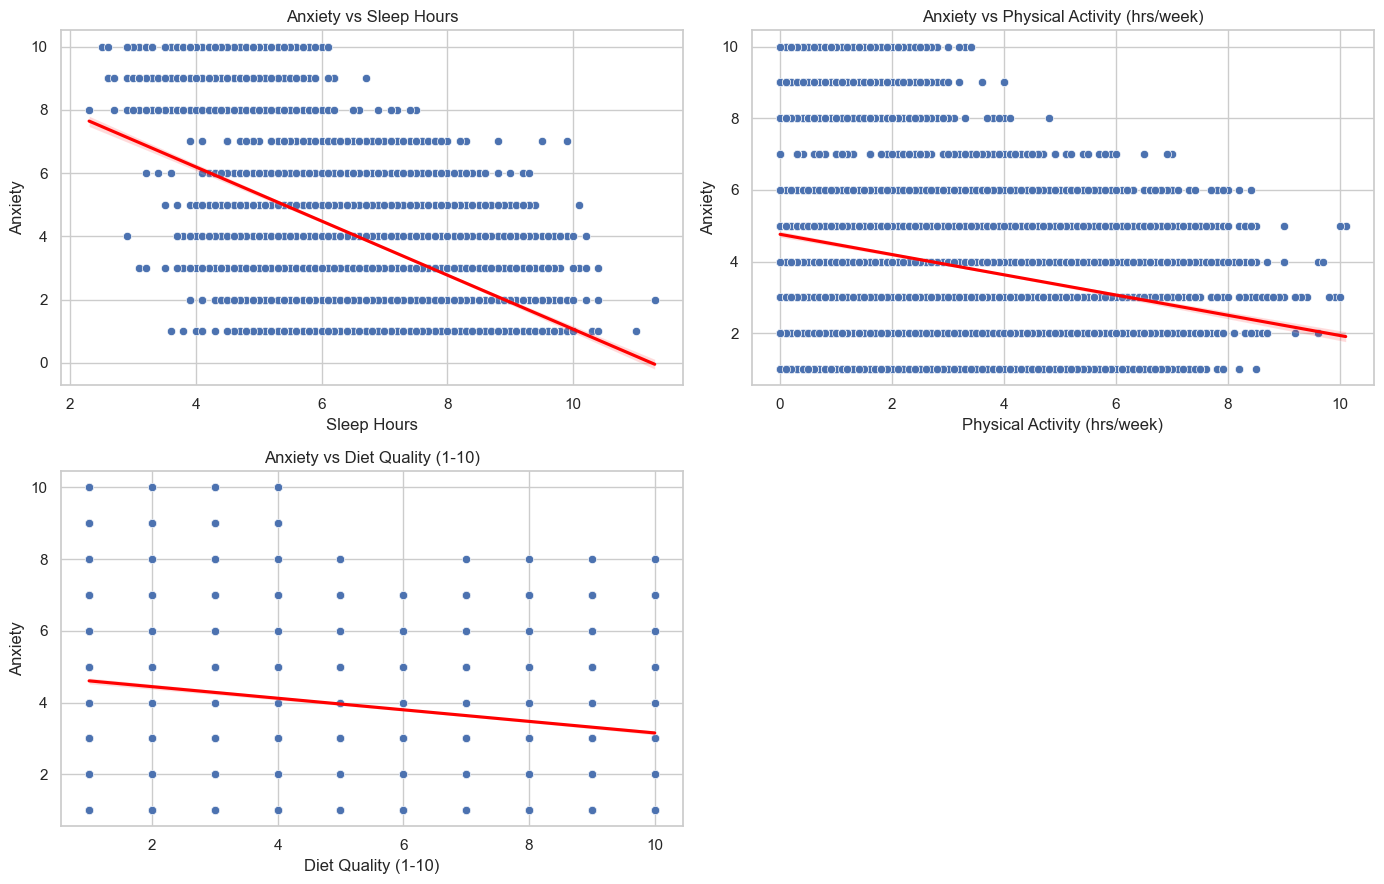

In [ ]:
# create columns
anx_col = 'Anxiety Level (1-10)'
lifestyle_col = [
    'Sleep Hours',
    'Physical Activity (hrs/week)',
    'Diet Quality (1-10)'
]

# create plots
plt.figure(figsize=(14, 9))

# create a plot for each lifestyle factor
for i in range(len(lifestyle_col)):
    # creates 2x2 grid (4 spaces) for each plot
    plt.subplot(2, 2, i+1)
    # assign column name of lifestyle factor to x col
    xcol = lifestyle_col[i]
    # create scatter plot and then plot the regression line
    sns.scatterplot(x=xcol, 
                    y=anx_col, 
                    data=df)
    sns.regplot(x=xcol, 
                y=anx_col, 
                data=df, 
                scatter=False, 
                color='Red')
    plt.xlabel(xcol)
    plt.ylabel('Anxiety')
    
    # use format to insert the column names in 
    plt.title(f'Anxiety vs {xcol}')
plt.tight_layout()

##### *Creates a mean regression line for the lifestyle factors together and compares to anxiety.*

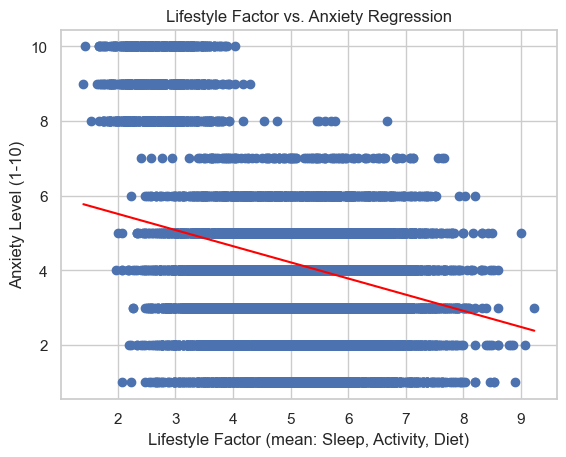

In [ ]:
# create columns
anx = 'Anxiety Level (1-10)'
f = ['Sleep Hours', 
     'Physical Activity (hrs/week)', 
     'Diet Quality (1-10)']

# create two arrays for slopes and intercepts
slopes = []
intercepts = []

# create plot points
for col in f:
    # get factor value and anxiety value at that point
    x = df[col]
    y = df.loc[x.index, anx]
    x_mean = x.mean()
    y_mean = y.mean()
    # get mean slope
    m = ((x - x_mean) * (y - y_mean)).sum() / ((x - x_mean)**2).sum()
    # get intercepts
    b = y_mean - m * x_mean
    # append values to slopes and intercepts arrays
    slopes.append(m)
    intercepts.append(b)

# mean slope and intercept
mean_slope = sum(slopes) / len(slopes)
mean_intercept = sum(intercepts) / len(intercepts)

# get mean for the plot, create new column and then find the mean for each row @ 'axis=1'
df['lifestyle_vs_anxiety'] = df[f].mean(axis=1)

# plot scatter and mean regression line
plt.scatter(df['lifestyle_vs_anxiety'], 
            df[anx])

# create line from min to max of the newly created column of values
x_line = [df['lifestyle_vs_anxiety'].min(), 
          df['lifestyle_vs_anxiety'].max()]

# find y values for the slope, start at min to max (2 values in the xline array)
x1 = x_line[0]
x2 = x_line[1]
y1 = mean_intercept + mean_slope * x1
y2 = mean_intercept + mean_slope * x2

y_line = [y1, y2]

# plot the graph
plt.plot(x_line, 
         y_line,
         color = 'Red')

plt.xlabel('Lifestyle Factor (mean: Sleep, Activity, Diet)')
plt.ylabel('Anxiety Level (1-10)')
plt.title('Lifestyle Factor vs. Anxiety Regression'); # semicolon = stops matplotlib from printing the text line



### **Stress Factors**

#### *Creates a mean regression line for stress, and leaves out family history of recent major life event. We are assuming they correlate to the stress factor for the purpose of this analysis.*

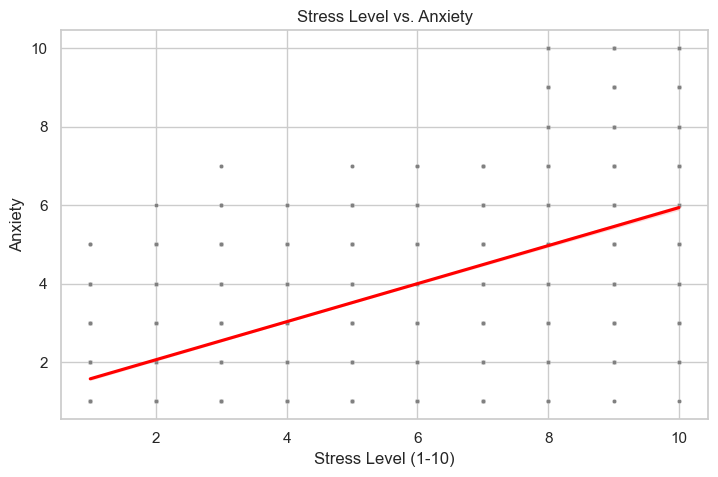

In [ ]:
# create columns
anx_col = 'Anxiety Level (1-10)'
factors = [
    # had to eliminate the two boolean options
    'Stress Level (1-10)',
]

# create plot
plt.figure(figsize=(14, 9))


# make sub dataframe
sub = df.copy()
sub['Family History of Anxiety'] = sub['Family History of Anxiety'].map({'Yes':1, 'No':0})
sub['Recent Major Life Event']   = sub['Recent Major Life Event'].map({'Yes':1, 'No':0})

#create a plot for each lifestyle factor
for i in range(len(factors)):
    # creates 2x2 grid (4 spaces) for each plot
    plt.subplot(2, 2, i+1)
    # assign column name of lifestyle factor to xcolumn
    xcol = factors[i]
    # create scatter plot and then plot the regression line

    sns.scatterplot(x=xcol, y=anx_col, data=sub, s=10, color='gray')
    sns.regplot(x=xcol, y=anx_col, data=sub, scatter=False, color='red')
    
    plt.xlabel(xcol)
    plt.ylabel('Anxiety')

plt.title('Stress Level vs. Anxiety')
plt.tight_layout()



---
#### **Discussion**
#### ***Summary of Examnination, and Findings:***
##### The dataset is comprised of 11,000 rows. There were origianlly 26 columns, however 17 of the columns were removed for relevancy when cleaning data (manually) and saved as a "mod" version of the data set as it was modified.

#### The data contained 11,000 entries from people aged 18 to 64, with a fairly balanced gender distribution (approx.): 33% male, 34% female, and 33% other. After examination, it was determined that there were no missing values in the data set. The gender percentages are close to the expected average, showing a diverse population - which is ideal. This was determined using calculated and visualized data as well, such as gender counts, gender percentages of total, and deviation from mean.

##### After examining the impact of **demographics** (age, gender) on the anxiety level, it was determined that demographics such as age and gender had very little effect on social anxiety. Younger individuals showed a slight upwards trend towards higher anxiety levels, and females had slightly higher social anxiety than males or other genders, but overall these differences were small and therefore not significant.

##### Afterwards, it was observed how **Lifestyle factors** (including sleep, physical activity, and diet quality) showed a stronger relationship with social anxiety via both calculated and visualized data. The average sleep was 6.65 hours, physical activity 2.94 hours/week, and diet quality 5.18/10. After further investigation, sleep had the largest impact, physical activity a moderate impact, and diet quality the least impact. When combined and visualized using linear regression, lower sleep, less exercise, and poorer diet were clearly linked to higher social anxiety levels.

##### Also, **Stress factor** also had a strong association with social anxiety. The average stress level was 5.86/10, and over half of the population reported a family history of social anxiety or a recent major life event. Higher stress was strongly correlated with higher social anxiety, while family history and major life events had smaller effects (unable to visualize).

##### Overall, the results suggest that demographics play a minor role in social anxiety levels, whereas stress and poor lifestyle habits are the main contributors to higher social social anxiety. Individuals with high stress, poor sleep, low physical activity, or low diet quality are more likely to experience higher social anxiety. This highlights that addressing stress and improving lifestyle factors may be the most effective way to reduce social anxiety, while age and gender are not prevelant factors.

---


---
### **Gen AI Disclosure:**

##### **Gen AI was utilized during this assignment for library commands and learning proper notation with markdown, learning about linear regression and statistics, learning how to use various plots, and graphs, and also how to use subplots (included youtue videos). So here are some examples of what was asked. An example is: command: "markdown syntax commands for jupyter notebook" response (will not be able to see as described in the text as it will modify the output as per the command it is illustrating):**

Here’s a clean, complete list of Markdown syntax commands you can use in Jupyter Notebook, organized by what they do.

📌 Jupyter Notebook Markdown Cheat Sheet

Markdown cells support standard Markdown + some extra LaTeX math.

1. Headings
# Heading 1
## Heading 2
### Heading 3
#### Heading 4
##### Heading 5
###### Heading 6

2. Text Styling
*italic*  
_italic_

**bold**  
__bold__

***bold italic***

~~strikethrough~~

... ETC
---

##### **Another use: *how to use seaborn, matplotlib and pandas to create a scatterplot and linear regressive line representation of data***

bsolutely! Let’s break this down step by step and show how Pandas, Matplotlib, and Seaborn can be combined to create a scatter plot with a linear regression line. I’ll also give a concrete Python example.

1. Setup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

2. Example Dataset

We’ll create a small dataset representing hours studied vs exam scores:

data = pd.DataFrame({
    'Study_Hours': [2, 3, 5, 7, 8, 10, 12, 15, 16, 18],
    'Exam_Score': [50, 55, 65, 70, 75, 80, 88, 90, 95, 98]
})

3. Using Matplotlib + Pandas
a) Scatter Plot
plt.scatter(data['Study_Hours'], data['Exam_Score'], color='blue', label='Data points')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Scatter Plot of Exam Score vs Study Hours')
plt.legend()
plt.show()

b) Add Linear Regression Line Manually

You can calculate the linear regression line using numpy or pandas:

import numpy as np

 Fit a linear regression (least squares)
slope, intercept = np.polyfit(data['Study_Hours'], data['Exam_Score'], 1)
line = slope * data['Study_Hours'] + intercept


 Plot
plt.scatter(data['Study_Hours'], data['Exam_Score'], color='blue', label='Data points')
plt.plot(data['Study_Hours'], line, color='red', label='Regression Line')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Scatter Plot with Regression Line')
plt.legend()
plt.show()

4. Using Seaborn

Seaborn makes it simpler because it can add a regression line automatically:

sns.set(style="whitegrid")  # nicer style
sns.regplot(x='Study_Hours', y='Exam_Score', data=data, ci=None, color='green', marker='o')
plt.title('Scatter Plot with Linear Regression (Seaborn)')
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.show()


ci=None removes the confidence interval shading if you don’t want it.

regplot automatically fits a linear regression line to the scatter points.

5. Practical Notes

Matplotlib is flexible but requires manual calculation of regression.

Seaborn is high-level, automatically handles regression and styling.

Pandas is used to store and manipulate data easily before plotting.

---

##### **Another use of Gen AI was to generate an APA citation for the dataset CSV:**
##### create a APA reference to this dataset CSV: https://www.kaggle.com/datasets/natezhang123/social-anxiety-dataset?resource=download

Here’s how you can format an APA 7th edition reference for that dataset:

Reference:

Zhang, N. (n.d.). Social anxiety dataset [Data set]. Kaggle. https://www.kaggle.com/datasets/natezhang123/social-anxiety-dataset

---

#### **The third use was for general questions like:** "Whats a cross analysis in an EDA" 
Response (including examples): 

In the context of Exploratory Data Analysis (EDA), a cross analysis (sometimes called a cross-tabulation analysis) is a technique used to examine the relationship between two or more variables in your dataset. Essentially, it’s about looking at how different variables interact with each other, often by summarizing them in a table or chart.

Here’s a breakdown:

1. Purpose

To identify patterns, correlations, or associations between variables.

To understand how one variable varies depending on another.

To spot trends, anomalies, or outliers when two dimensions are considered together.

2. Common Methods

Cross-tabulation (crosstab): A table that shows the frequency or proportion of data points for combinations of two categorical variables.
Example in Python with pandas:

import pandas as pd

--Comment-- Suppose df has columns 'Gender' and 'Social_Anxiety_Level'
cross_tab = pd.crosstab(df['Gender'], df['Social_Anxiety_Level'])
print(cross_tab)


Pivot tables: Like cross-tabs but more flexible; can include aggregation functions like mean, sum, etc.

Grouped statistics: Using groupby to analyze numeric data across categories.

---

#### **Another use: "how to use matplotlib and seaborn to create various graphs and data visualizations and examples of how i would use them in python (After which I asked to breakdown all the syntax to better understand all the variability). Repsonse: "**

Absolutely! Let’s go step by step. I’ll explain how Matplotlib and Seaborn are used to create different types of graphs and give concrete Python examples. These are two of the most commonly used libraries for data visualization in Python.

1. Setup

First, make sure you have the libraries installed:

pip install matplotlib seaborn


Then, import them in Python:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


We’ll use a sample dataset for demonstration:

1. Setup
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

Example dataset:


data = pd.DataFrame({
    'Student': ['Alice', 'Bob', 'Charlie', 'David', 'Eva', 'Frank', 'Grace', 'Hannah', 'Ian', 'Jane'],
    'Study_Hours': [5, 12, 9, 4, 8, 10, 6, 7, 11, 3],
    'Exam_Score': [65, 90, 78, 50, 82, 88, 70, 75, 92, 45],
    'Section': ['A', 'B', 'A', 'C', 'B', 'A', 'C', 'B', 'C', 'A']
})

2. Matplotlib Visualizations
a) Line Plot – Study Hours vs Exam Score
plt.plot(data['Study_Hours'], data['Exam_Score'], marker='o', color='purple')
plt.title("Exam Score vs Study Hours")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()

b) Bar Chart – Average Exam Score by Section
avg_score = data.groupby('Section')['Exam_Score'].mean()

plt.bar(avg_score.index, avg_score.values, color='teal')
plt.title("Average Exam Score by Section")
plt.xlabel("Section")
plt.ylabel("Average Score")
plt.show()

c) Histogram – Distribution of Study Hours
plt.hist(data['Study_Hours'], bins=5, color='orange', edgecolor='black')
plt.title("Distribution of Study Hours")
plt.xlabel("Hours")
plt.ylabel("Number of Students")
plt.show()

d) Scatter Plot – Study Hours vs Exam Score
plt.scatter(data['Study_Hours'], data['Exam_Score'], c='green')
plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()

3. Seaborn Visualizations
a) Bar Plot – Average Exam Score by Section
sns.barplot(x='Section', y='Exam_Score', data=data)
plt.title("Average Exam Score by Section")
plt.show()

b) Count Plot – Number of Students per Section
sns.countplot(x='Section', data=data, palette='pastel')
plt.title("Number of Students per Section")
plt.show()

c) Box Plot – Exam Score by Section
sns.boxplot(x='Section', y='Exam_Score', data=data)
plt.title("Exam Score Distribution by Section")
plt.show()

---




---

#### Data Source : 
https://www.kaggle.com/datasets/natezhang123/social-anxiety-dataset?resource=download

#### Citation (APA style Generated usng Chat GPT):
Zhang, N. (n.d.). Social anxiety dataset [Data set]. Kaggle. 
   https://www.kaggle.com/datasets/natezhang123/social-anxiety-dataset

---